In [1]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

Selecting previously unselected package fonts-nanum.
(Reading database ... 126209 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...


In [2]:
# 나눔고딕으로 폰트 변경
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'NanumGothic'

In [3]:
# matplot의 폰트와 폰트 크기 확인
print(plt.rcParams['font.family'], plt.rcParams['font.size'])

['NanumGothic'] 10.0


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 필요하다고 판단되는 라이브러리를 추가하세요.
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
# from sklearn.preprocessing import LabelEncoder
# from xgboost import XGBClassifier
# import lightgbm as lgb
from sklearn.model_selection import train_test_split, GridSearchCV ,cross_validate
from sklearn.metrics import *
import joblib

In [5]:
default_data = pd.read_csv('모델 정확도(디폴트_fi_pca).csv')
paper_data = pd.read_csv('모델 정확도(논문 기준_fi_pca).csv')
gs_data = pd.read_csv('모델 정확도(그리드서치_fi_pca).csv')

In [6]:
default_data.head()

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.936587,0.935977
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.962827,0.972238
2,SVM,0.968203,0.973487,0.968883,0.970768,0.960400,0.971105
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.850826,0.849858


In [7]:
default_data_tmp = default_data.set_index('모델')
default_data_tmp

,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트)
모델,,,,,,
RandomForest,0.977215,0.978246,0.979596,0.978246,0.936587,0.935977
LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.962827,0.972238
SVM,0.968203,0.973487,0.968883,0.970768,0.960400,0.971105
DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.850826,0.849858


In [8]:
paper_data.head()

,모델,논문_정확도(교차검증),논문_정확도(테스트),논문_정확도(fi_교차검증),논문_정확도(fi_테스트),논문_정확도(pca_교차검증),논문_정확도(pca_테스트)
0,RandomForest,0.951892,0.945042,0.947276,0.975637,0.886778,0.892351
1,LogisticRegression,0.981778,0.987535,0.974731,0.980737,0.962341,0.971105
2,SVM,0.980078,0.985269,0.977891,0.980170,0.963314,0.976204
3,DecisionTreeClassifier,0.892851,0.880453,0.893823,0.879887,0.785713,0.806232


In [9]:
gs_data.head()

,모델,gs_정확도(교차검증),gs_정확도(테스트),gs_정확도(fi_교차검증),gs_정확도(fi_테스트),gs_정확도(pca_교차검증),gs_정확도(pca_테스트)
0,RandomForest,0.967444,0.964306,0.964528,0.964306,0.913992,0.920680
1,LogisticRegression,0.983721,0.984703,0.975702,0.985836,0.964528,0.971105
2,SVM,0.984207,0.988669,0.985665,0.991501,0.973761,0.982436
3,DecisionTreeClassifier,0.930028,0.932578,0.936586,0.937110,0.855197,0.857224


In [10]:
df = default_data.merge(paper_data, left_on=['모델'], right_on=['모델'])
df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),논문_정확도(교차검증),논문_정확도(테스트),논문_정확도(fi_교차검증),논문_정확도(fi_테스트),논문_정확도(pca_교차검증),논문_정확도(pca_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.936587,0.935977,0.951892,0.945042,0.947276,0.975637,0.886778,0.892351
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.962827,0.972238,0.981778,0.987535,0.974731,0.980737,0.962341,0.971105
2,SVM,0.968203,0.973487,0.968883,0.970768,0.960400,0.971105,0.980078,0.985269,0.977891,0.980170,0.963314,0.976204
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.850826,0.849858,0.892851,0.880453,0.893823,0.879887,0.785713,0.806232


In [11]:
df = df.merge(gs_data, left_on=['모델'], right_on=['모델'])
df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),논문_정확도(교차검증),논문_정확도(테스트),논문_정확도(fi_교차검증),논문_정확도(fi_테스트),논문_정확도(pca_교차검증),논문_정확도(pca_테스트),gs_정확도(교차검증),gs_정확도(테스트),gs_정확도(fi_교차검증),gs_정확도(fi_테스트),gs_정확도(pca_교차검증),gs_정확도(pca_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.936587,0.935977,0.951892,0.945042,0.947276,0.975637,0.886778,0.892351,0.967444,0.964306,0.964528,0.964306,0.913992,0.920680
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.962827,0.972238,0.981778,0.987535,0.974731,0.980737,0.962341,0.971105,0.983721,0.984703,0.975702,0.985836,0.964528,0.971105
2,SVM,0.968203,0.973487,0.968883,0.970768,0.960400,0.971105,0.980078,0.985269,0.977891,0.980170,0.963314,0.976204,0.984207,0.988669,0.985665,0.991501,0.973761,0.982436
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.850826,0.849858,0.892851,0.880453,0.893823,0.879887,0.785713,0.806232,0.930028,0.932578,0.936586,0.937110,0.855197,0.857224


In [12]:
df.to_csv('모델 정확도(종합).csv', index=False, encoding='utf-8-sig')

In [13]:
df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),논문_정확도(교차검증),논문_정확도(테스트),논문_정확도(fi_교차검증),논문_정확도(fi_테스트),논문_정확도(pca_교차검증),논문_정확도(pca_테스트),gs_정확도(교차검증),gs_정확도(테스트),gs_정확도(fi_교차검증),gs_정확도(fi_테스트),gs_정확도(pca_교차검증),gs_정확도(pca_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.936587,0.935977,0.951892,0.945042,0.947276,0.975637,0.886778,0.892351,0.967444,0.964306,0.964528,0.964306,0.913992,0.920680
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.962827,0.972238,0.981778,0.987535,0.974731,0.980737,0.962341,0.971105,0.983721,0.984703,0.975702,0.985836,0.964528,0.971105
2,SVM,0.968203,0.973487,0.968883,0.970768,0.960400,0.971105,0.980078,0.985269,0.977891,0.980170,0.963314,0.976204,0.984207,0.988669,0.985665,0.991501,0.973761,0.982436
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.850826,0.849858,0.892851,0.880453,0.893823,0.879887,0.785713,0.806232,0.930028,0.932578,0.936586,0.937110,0.855197,0.857224


In [14]:
df.set_index('모델', inplace=True)

In [15]:
df

,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),논문_정확도(교차검증),논문_정확도(테스트),논문_정확도(fi_교차검증),논문_정확도(fi_테스트),논문_정확도(pca_교차검증),논문_정확도(pca_테스트),gs_정확도(교차검증),gs_정확도(테스트),gs_정확도(fi_교차검증),gs_정확도(fi_테스트),gs_정확도(pca_교차검증),gs_정확도(pca_테스트)
모델,,,,,,,,,,,,,,,,,,
RandomForest,0.977215,0.978246,0.979596,0.978246,0.936587,0.935977,0.951892,0.945042,0.947276,0.975637,0.886778,0.892351,0.967444,0.964306,0.964528,0.964306,0.913992,0.920680
LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.962827,0.972238,0.981778,0.987535,0.974731,0.980737,0.962341,0.971105,0.983721,0.984703,0.975702,0.985836,0.964528,0.971105
SVM,0.968203,0.973487,0.968883,0.970768,0.960400,0.971105,0.980078,0.985269,0.977891,0.980170,0.963314,0.976204,0.984207,0.988669,0.985665,0.991501,0.973761,0.982436
DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.850826,0.849858,0.892851,0.880453,0.893823,0.879887,0.785713,0.806232,0.930028,0.932578,0.936586,0.937110,0.855197,0.857224


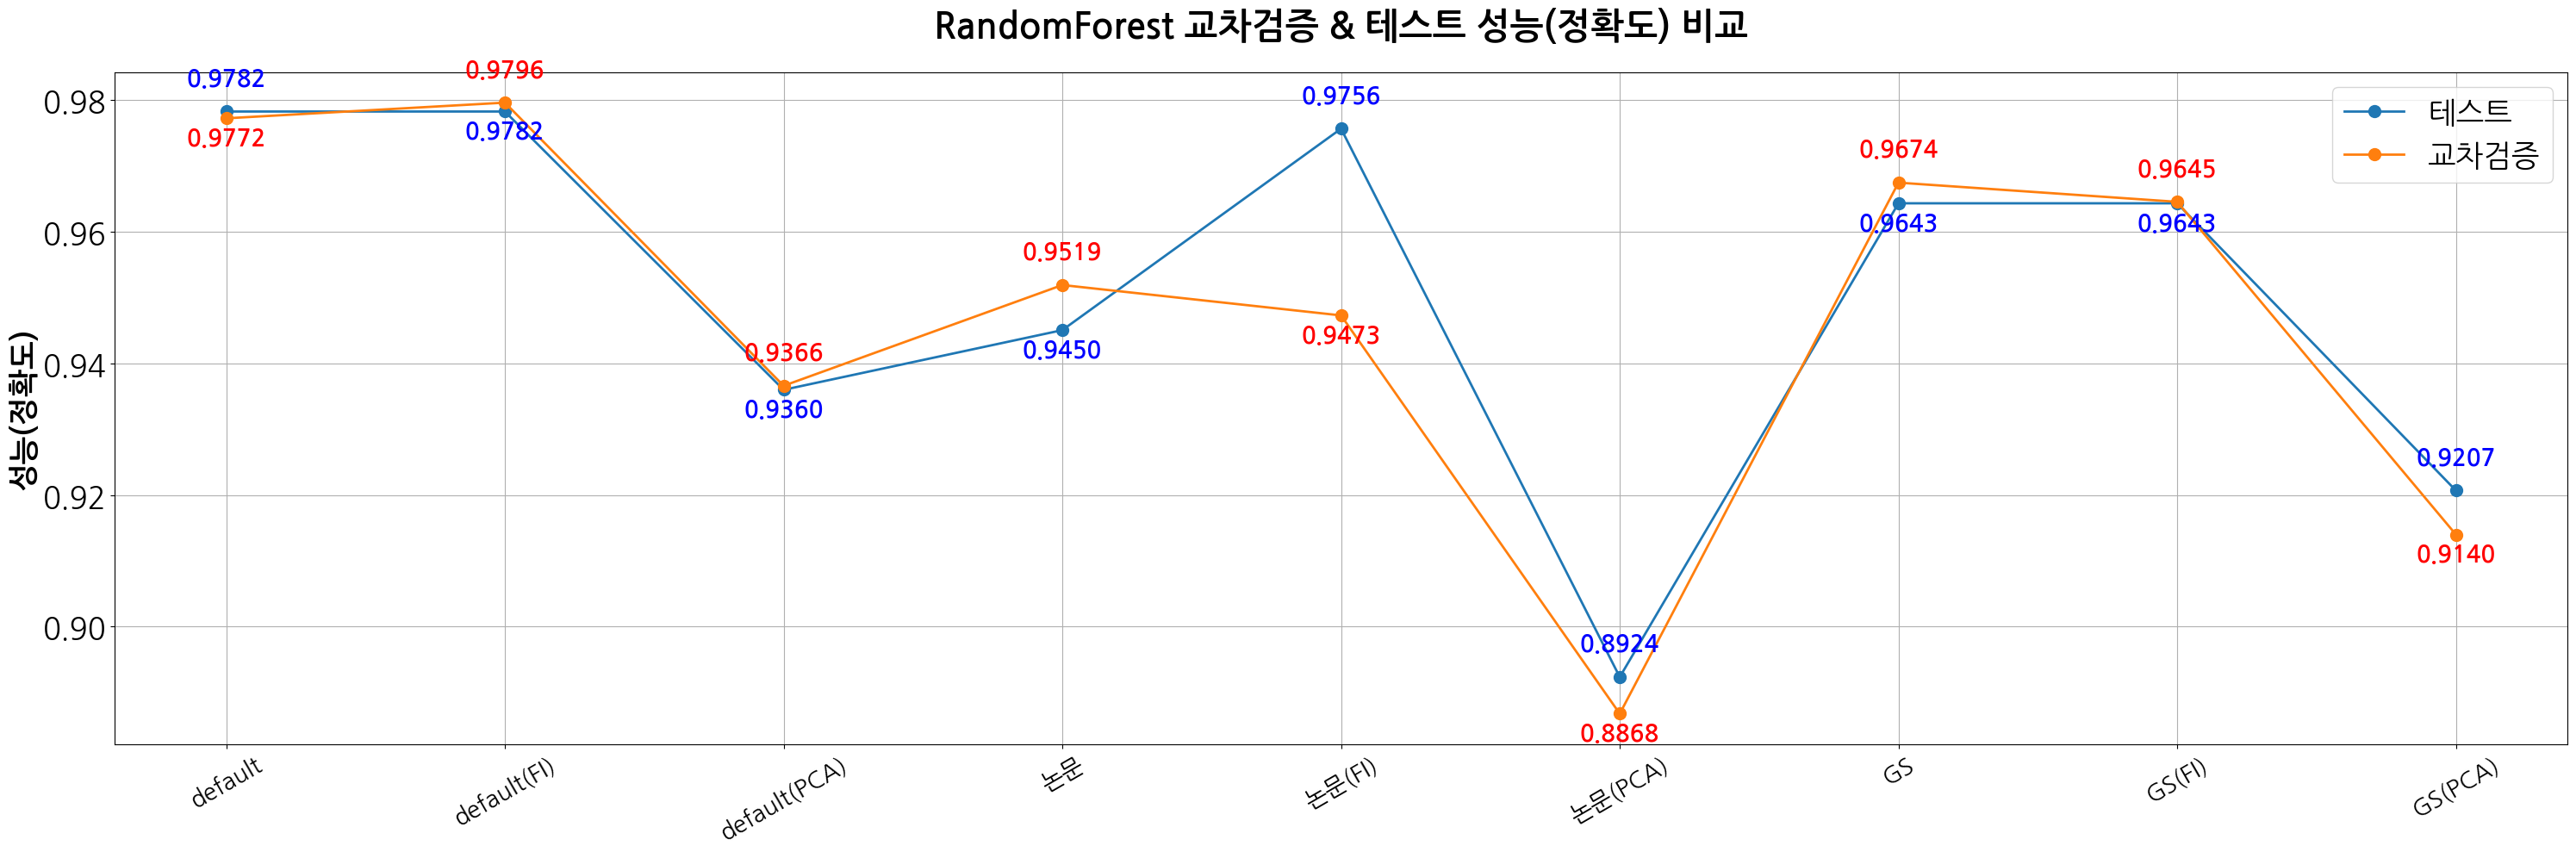

In [16]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)',
            '논문', '논문(FI)', '논문(PCA)',
            'GS', 'GS(FI)', 'GS(PCA)']

# RandomForest 테스트 및 교차검증 정확도 추출
rf_test = df.loc['RandomForest', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)'
]]

rf_cv = df.loc['RandomForest', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, rf_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, rf_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

# 각 지점에서 더 큰 값은 위, 더 작은 값은 아래에 표시
for i, (test_val, cv_val) in enumerate(zip(rf_test.values, rf_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.004, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.004, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.004, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.004, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')


# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("RandomForest 교차검증 & 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

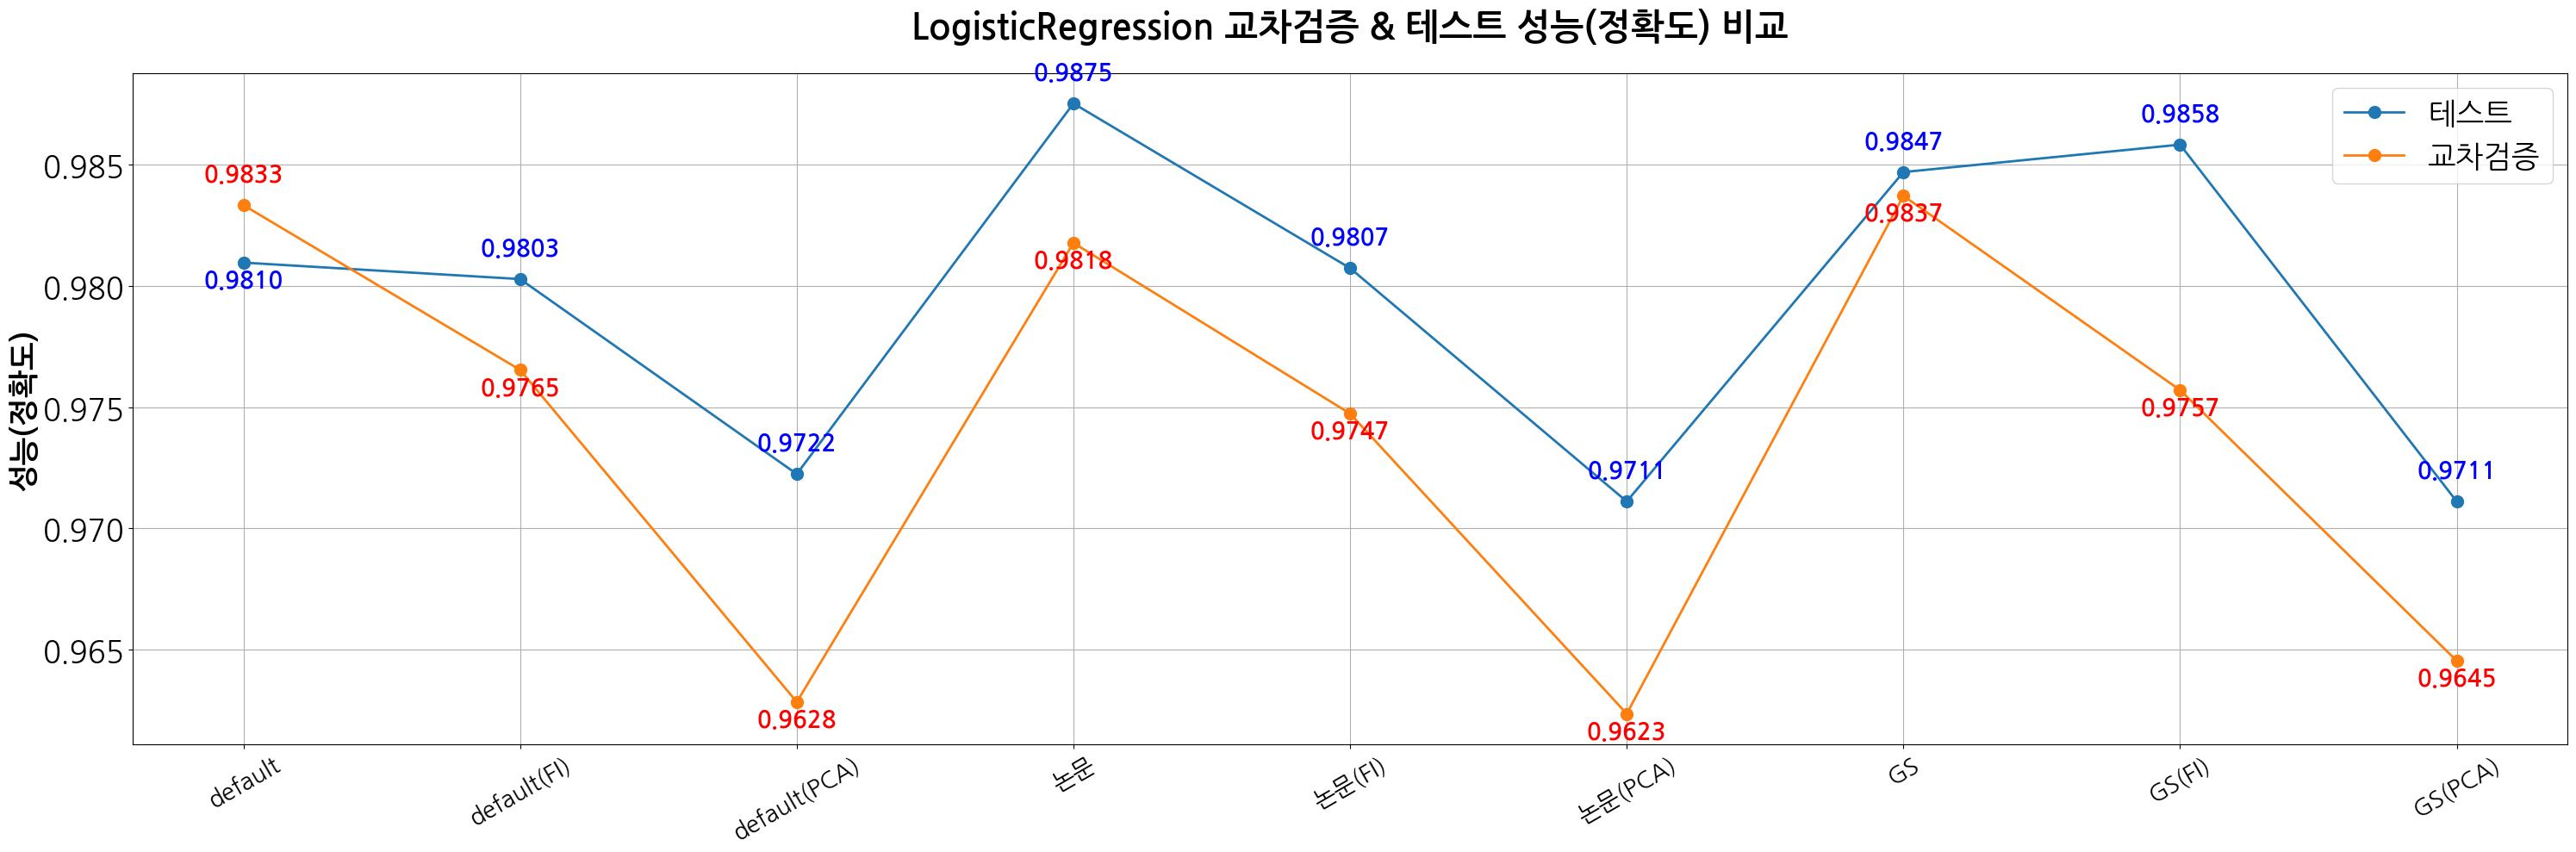

In [17]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)',
            '논문', '논문(FI)', '논문(PCA)',
            'GS', 'GS(FI)', 'GS(PCA)']

# LogisticRegression 테스트 및 교차검증 정확도 추출
lr_test = df.loc['LogisticRegression', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)'
]]

lr_cv = df.loc['LogisticRegression', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, lr_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, lr_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

# 각 지점에서 더 큰 값은 위, 더 작은 값은 아래에 표시
for i, (test_val, cv_val) in enumerate(zip(lr_test.values, lr_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.001, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.001, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.001, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.001, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')


# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("LogisticRegression 교차검증 & 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

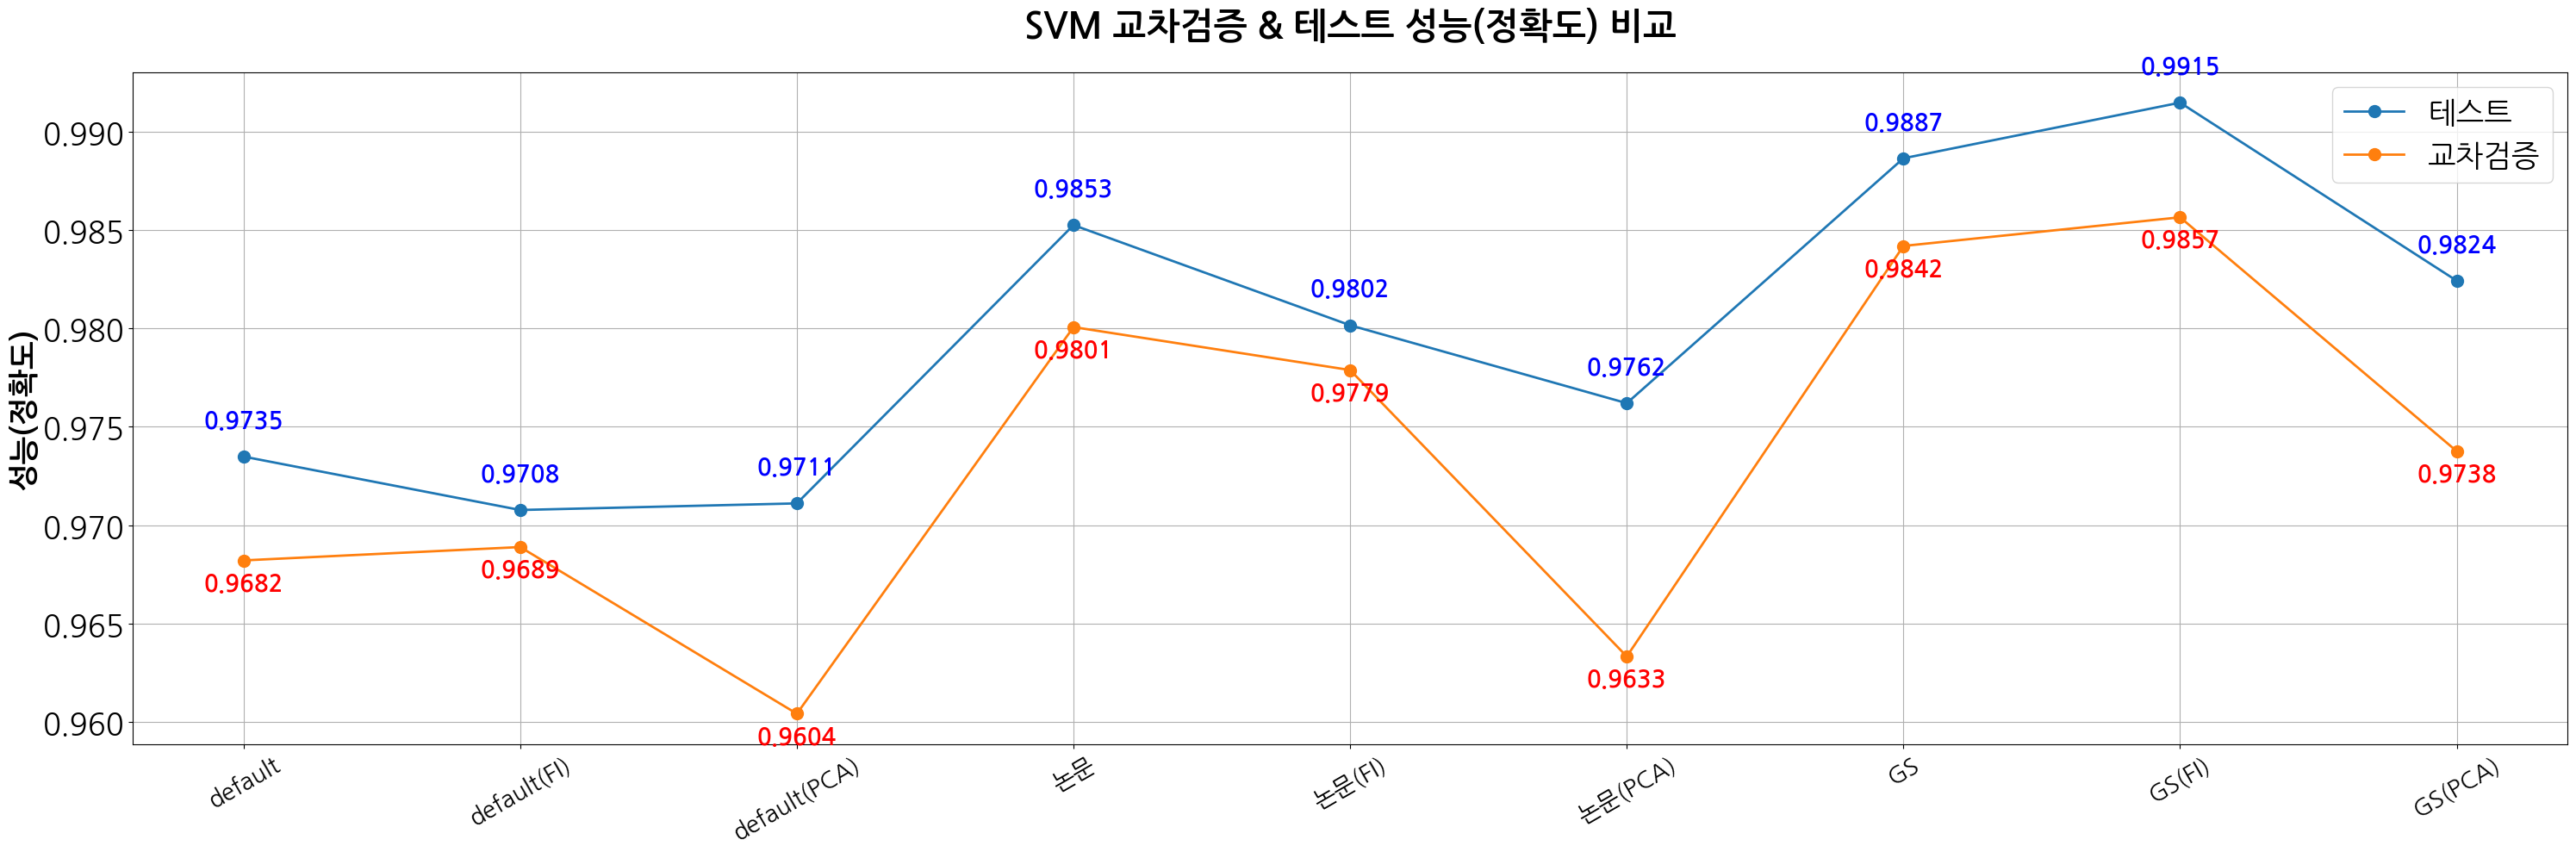

In [18]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)',
            '논문', '논문(FI)', '논문(PCA)',
            'GS', 'GS(FI)', 'GS(PCA)']

# LogisticRegression 테스트 및 교차검증 정확도 추출
svm_test = df.loc['SVM', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)'
]]

svm_cv = df.loc['SVM', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, svm_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, svm_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

for i, (test_val, cv_val) in enumerate(zip(svm_test.values, svm_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.0015, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.0015, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.0015, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.0015, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("SVM 교차검증 & 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

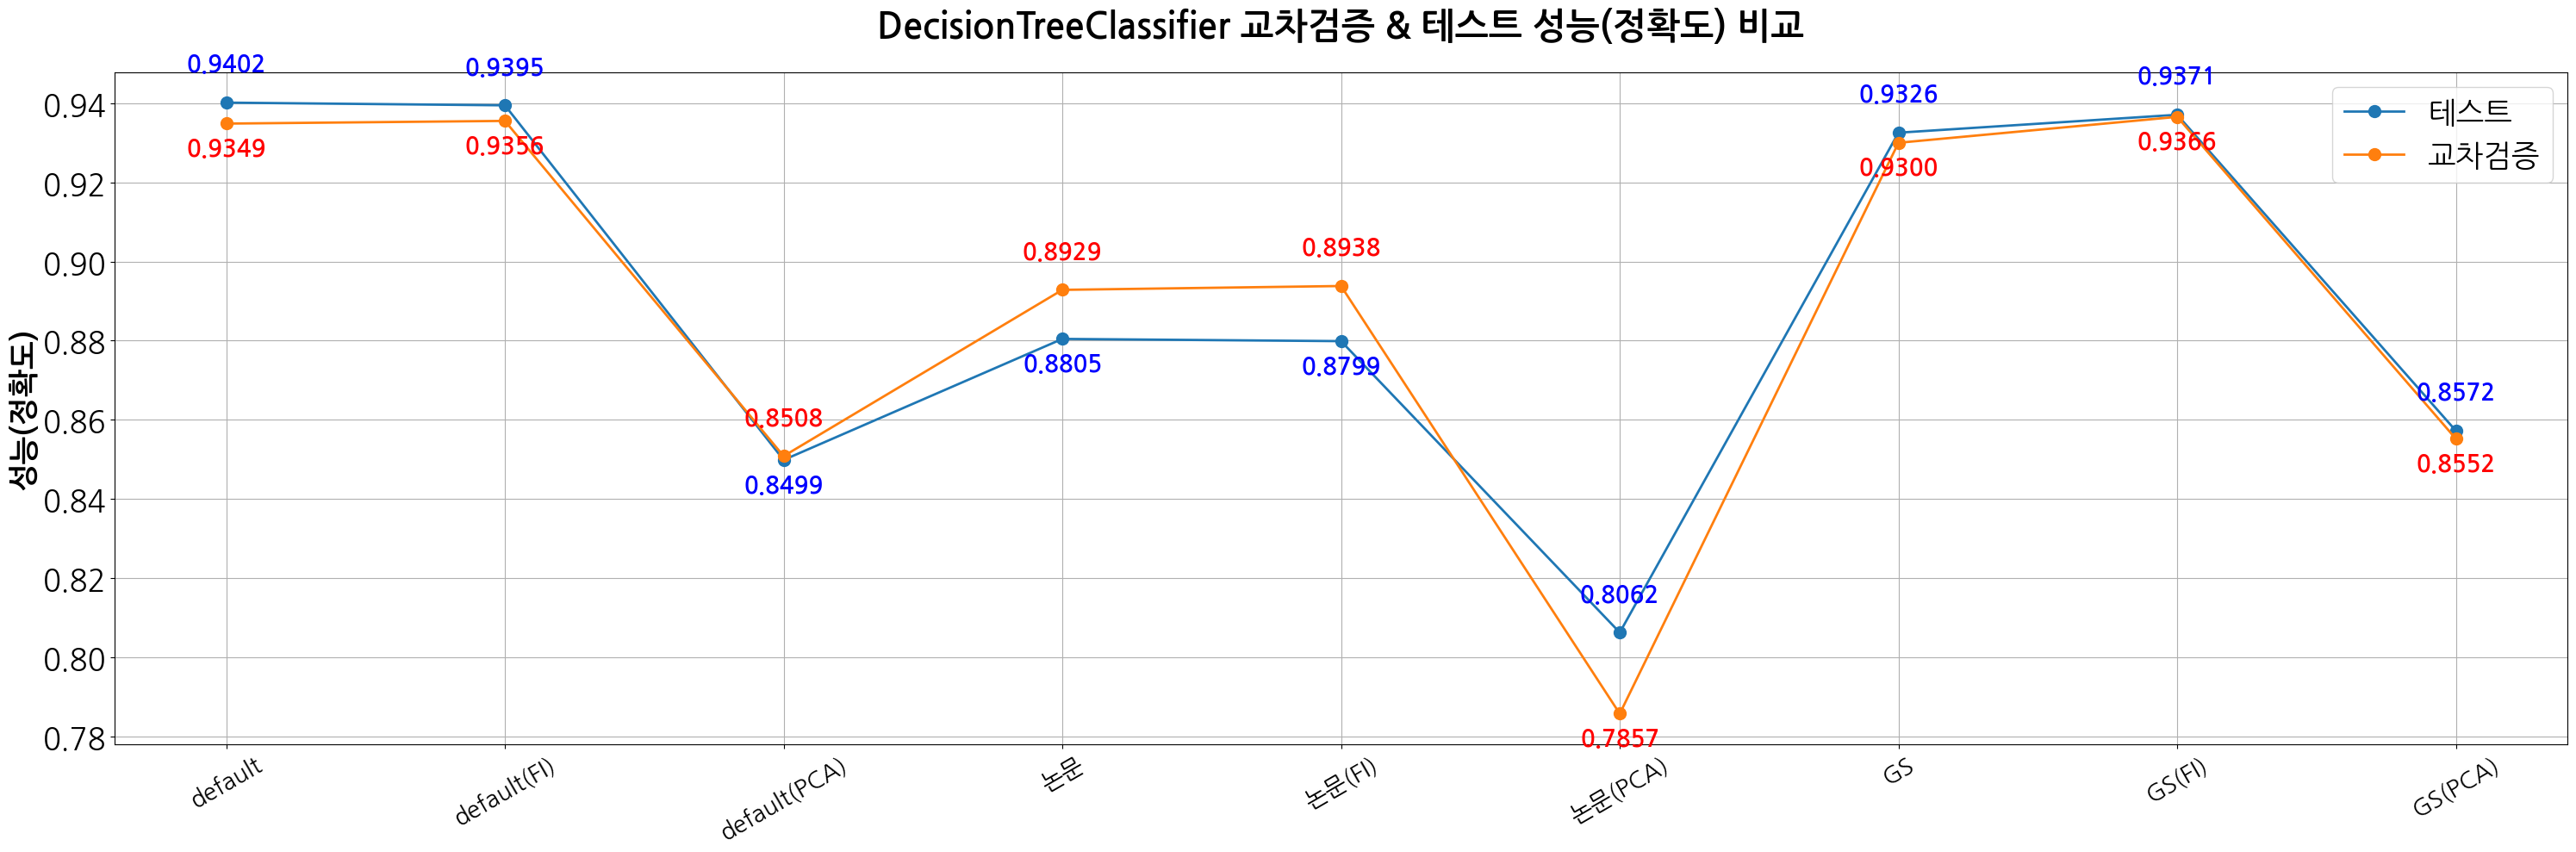

In [19]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)',
            '논문', '논문(FI)', '논문(PCA)',
            'GS', 'GS(FI)', 'GS(PCA)']

# LogisticRegression 테스트 및 교차검증 정확도 추출
dt_test = df.loc['DecisionTreeClassifier', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)'
]]

dt_cv = df.loc['DecisionTreeClassifier', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, dt_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, dt_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

for i, (test_val, cv_val) in enumerate(zip(dt_test.values, dt_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.008, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.008, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.008, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.008, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("DecisionTreeClassifier 교차검증 & 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

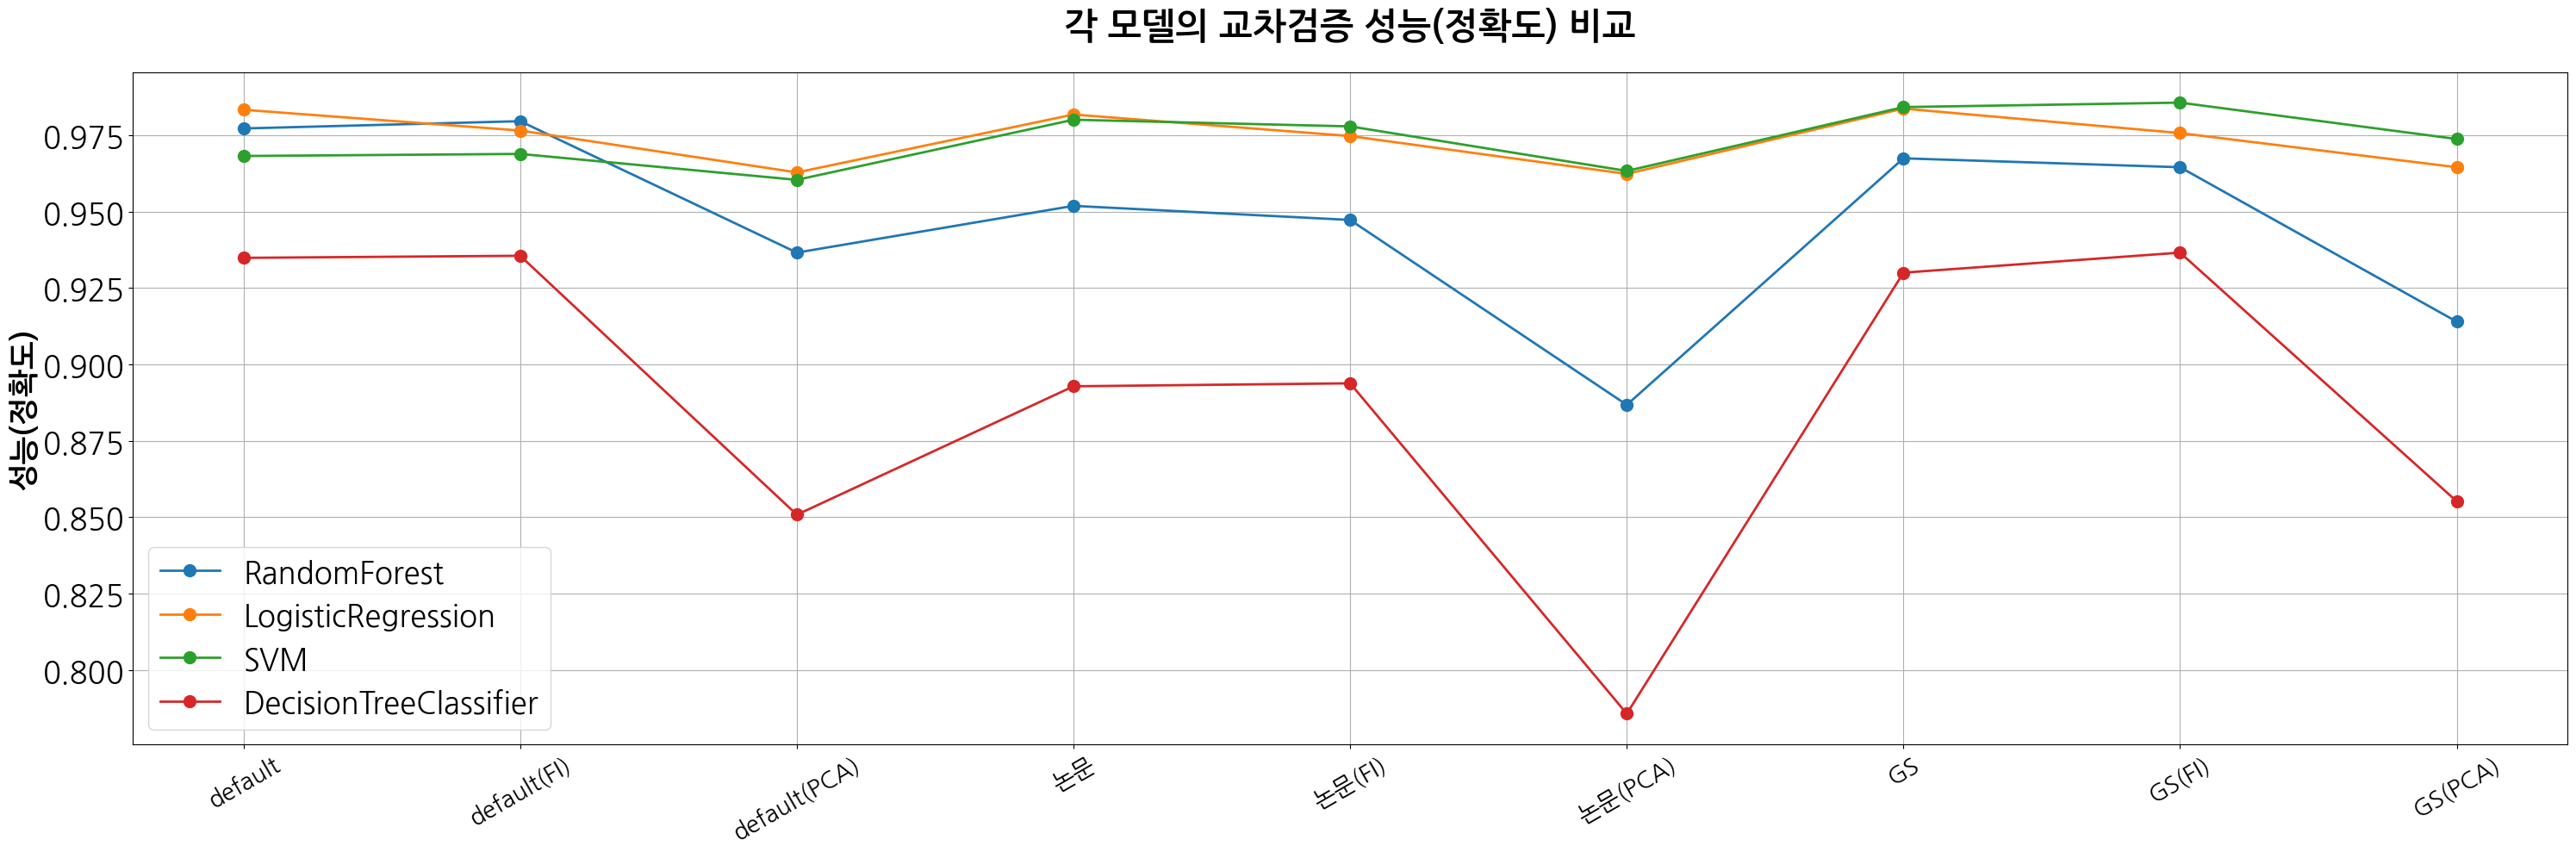

In [20]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)',
            '논문', '논문(FI)', '논문(PCA)',
            'GS', 'GS(FI)', 'GS(PCA)']

# RandomForest 테스트 및 교차검증 정확도 추출
rf_test = df.loc['RandomForest', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)'
]]

lr_test = df.loc['LogisticRegression', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)'
]]

svm_test = df.loc['SVM', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)'
]]

dt_test = df.loc['DecisionTreeClassifier', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, rf_test.values, marker='o', markersize=10, linewidth=2, label='RandomForest')
plt.plot(x_labels, lr_test.values, marker='o', markersize=10, linewidth=2, label='LogisticRegression')
plt.plot(x_labels, svm_test.values, marker='o', markersize=10, linewidth=2, label='SVM')
plt.plot(x_labels, dt_test.values, marker='o', markersize=10, linewidth=2, label='DecisionTreeClassifier')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("각 모델의 교차검증 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

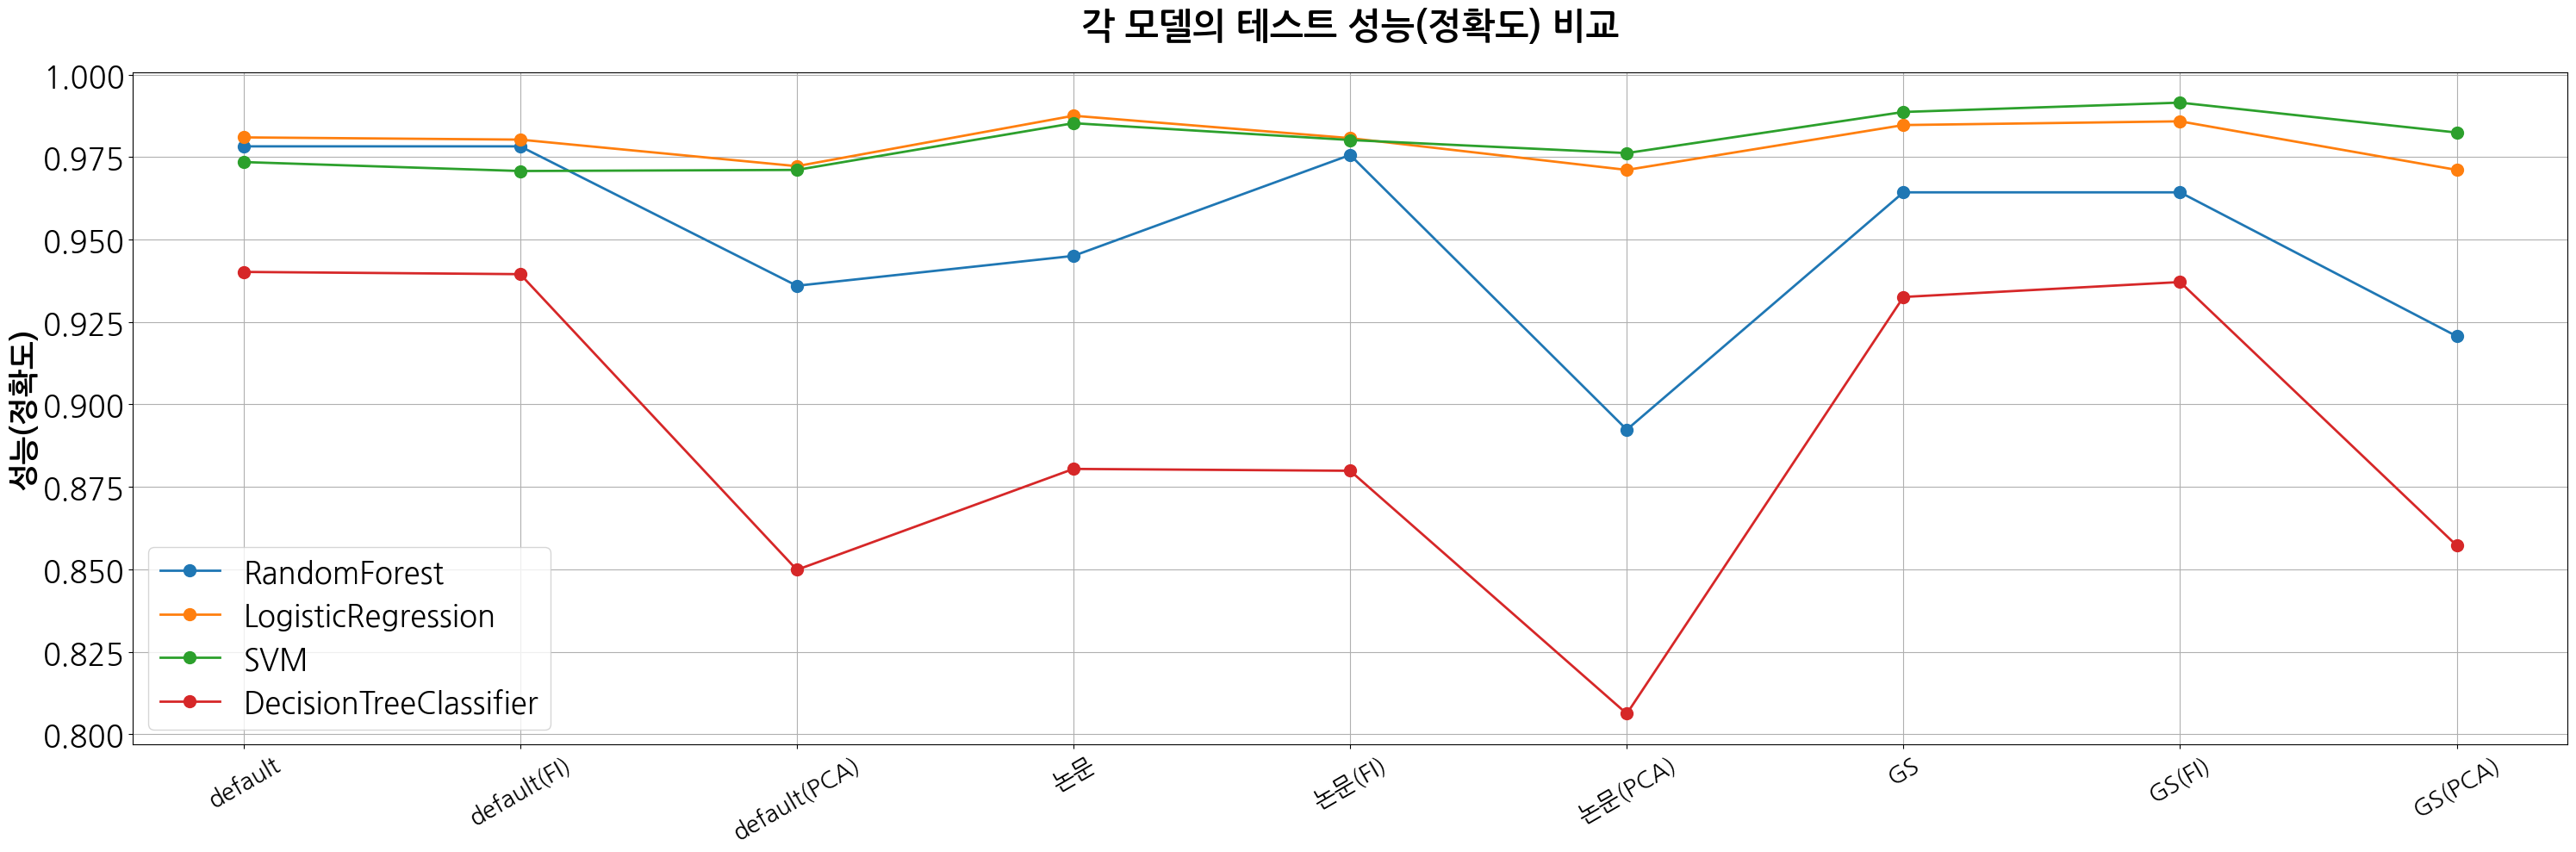

In [21]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)',
            '논문', '논문(FI)', '논문(PCA)',
            'GS', 'GS(FI)', 'GS(PCA)']

# RandomForest 테스트 및 교차검증 정확도 추출
rf_test = df.loc['RandomForest', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)'
]]

lr_test = df.loc['LogisticRegression', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)'
]]

svm_test = df.loc['SVM', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)'
]]

dt_test = df.loc['DecisionTreeClassifier', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, rf_test.values, marker='o', markersize=10, linewidth=2, label='RandomForest')
plt.plot(x_labels, lr_test.values, marker='o', markersize=10, linewidth=2, label='LogisticRegression')
plt.plot(x_labels, svm_test.values, marker='o', markersize=10, linewidth=2, label='SVM')
plt.plot(x_labels, dt_test.values, marker='o', markersize=10, linewidth=2, label='DecisionTreeClassifier')

# # 각 지점에 정확도 주석 달기 (겹치지 않게 위/아래로)
# for i, (test_val, cv_val) in enumerate(zip(rf_test.values, rf_cv.values)):
#     plt.text(i, test_val + 0.005, f"{test_val:.4f}", ha='center', fontsize=20, color='blue')
#     plt.text(i, cv_val - 0.005, f"{cv_val:.4f}", ha='center', fontsize=20, color='red')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("각 모델의 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()